In [8]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import deepxde as dde 
dde.config.disable_xla_jit()
from deepxde.backend import tf
from functools import reduce
import argparse

parser = argparse.ArgumentParser(description='Set parameters')


Disable just-in-time compilation with XLA.



no uniform points
Compiling model...
'compile' took 0.000347 s

Training model...

Step      Train loss    Test loss     Test metric   
0         [1.52e+05]    [1.54e+05]    [1.00e+00]    
1000      [4.79e+04]    [6.01e+04]    [9.41e-01]    
2000      [1.18e+03]    [1.45e+03]    [6.03e-01]    
3000      [1.86e+02]    [2.58e+02]    [3.51e-01]    
4000      [9.39e+01]    [1.12e+02]    [2.10e-01]    
5000      [2.50e+01]    [3.59e+01]    [1.17e-01]    
6000      [1.49e+01]    [2.01e+01]    [7.67e-02]    
7000      [1.33e+01]    [1.74e+01]    [5.82e-02]    
8000      [1.13e+02]    [1.13e+02]    [4.59e-02]    
9000      [7.36e+01]    [9.02e+01]    [1.38e-01]    
10000     [2.83e+02]    [2.88e+02]    [6.43e-02]    

Best model at step 7000:
  train loss: 1.33e+01
  test loss: 1.74e+01
  test metric: [5.82e-02]

'train' took 814.822328 s

Saving loss history to /root/shared/UQ/Tensor-PINNs/Helmholtz/loss.dat ...
Saving training data to /root/shared/UQ/Tensor-PINNs/Helmholtz/train.dat ...
Savi

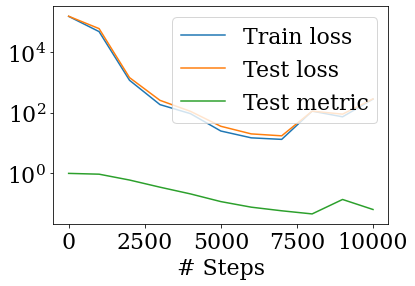

In [9]:
import deepxde as dde 

#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

# General parameters
n = 1
N_f = 5000
N_f_test = 5000

#epochs = 10000 
epochs = 10000
#parameters = [1e-3, 4, 50, "sin"] gives 0.5
parameters = [1e-2, 2, 350, "sin"] 

# Define sine function
if dde.backend.backend_name == "pytorch":
    sin = dde.backend.pytorch.sin
else:
    from deepxde.backend import tf
    sin = tf.sin

learning_rate, num_dense_layers, num_dense_nodes, activation = parameters


def pde(x, y):
    dy1_xx = dde.grad.hessian(y, x, i=0, j=0)
    dy1_yy = dde.grad.hessian(y, x, i=1, j=1)

    dy1_zz = dde.grad.hessian(y, x, i=2, j=2)
    dy1_tt = dde.grad.hessian(y, x, i=3, j=3)

    D1 = dy1_xx + dy1_yy
    D2 = dy1_zz + dy1_tt
    
    
    D1D2 = dde.grad.hessian(D2, x, i=0, j=0) + dde.grad.hessian(D2, x, i=1, j=1)
    
    A = D1D2 + k0 ** 2* D1 + k0 ** 2 * D2 + k0 ** 4 * y
    F = k0 ** 4 * sin(k0 * x[:, 0:1]) * sin(k0 * x[:, 1:2]) * sin(k0 * x[:, 2:3]) * sin(k0 * x[:, 3:4])

    res = A - F
    return res


def func(x):
    f1 = np.sin(k0 * x[:, 0:1]) * np.sin(k0 * x[:, 1:2])
    f2 = np.sin(k0 * x[:, 2:3]) * np.sin(k0 * x[:, 3:4])
    return f1 * f2

def transform(x, y):
    res1 = x[:, 0:1] * (1 - x[:, 0:1]) * x[:, 1:2] * (1 - x[:, 1:2])
    res2 = x[:, 2:3] * (1 - x[:, 2:3]) * x[:, 3:4] * (1 - x[:, 3:4])
    return res1 * res2 * y
    #return (res1 * y) * (res2 * y)

def boundary(_, on_boundary):
    return on_boundary

geom = dde.geometry.Rectangle([0, 0], [1, 1])
Geom = GeometryXGeometry(geom,2)    

k0 = 2 * np.pi * n
wave_len = 1 / n

data = dde.data.PDE(
    Geom,
    pde,
    train_distribution = 'pseudo',
    num_domain=N_f,
    solution=func,
    bcs = [],
    num_test=N_f_test,
)

net = dde.nn.FNN(
    [4] + [num_dense_nodes] * num_dense_layers + [1], activation, "Glorot uniform"
)

net.apply_output_transform(transform)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate, metrics=["l2 relative error"])
losshistory, train_state = model.train(epochs=epochs)
dde.saveplot(losshistory, train_state, issave=True, isplot=True)
    

In [12]:
result = np.sum(
            [np.prod(v.get_shape().as_list()) for v in model.net.trainable_variables]
        )
print('Theta:= ', result)

Theta:=  124951


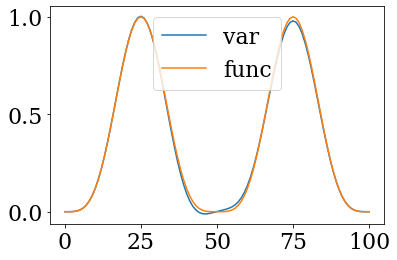

In [10]:
k = 2
from matplotlib import pyplot as plt
x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(2 * k)]
xx = np.concatenate(x_list).T
pred = model.predict(xx)
fig = plt.figure()
plt.plot(pred.ravel(), label=r'var')
plt.plot(func(xx), label=r'func')
plt.legend()

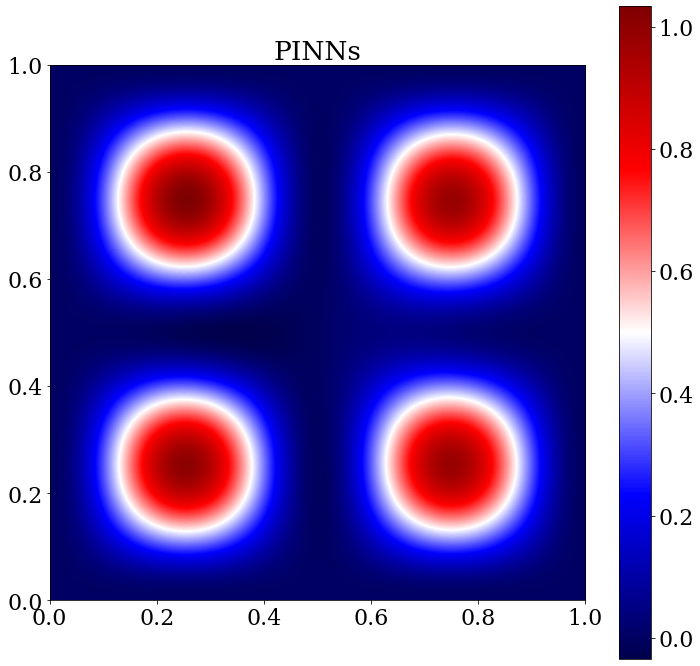

In [11]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_sca = model.predict(points_4d)
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='PINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('PINNs')
plt.savefig('solcov.pdf')

Relative error =  0.03889962957712107


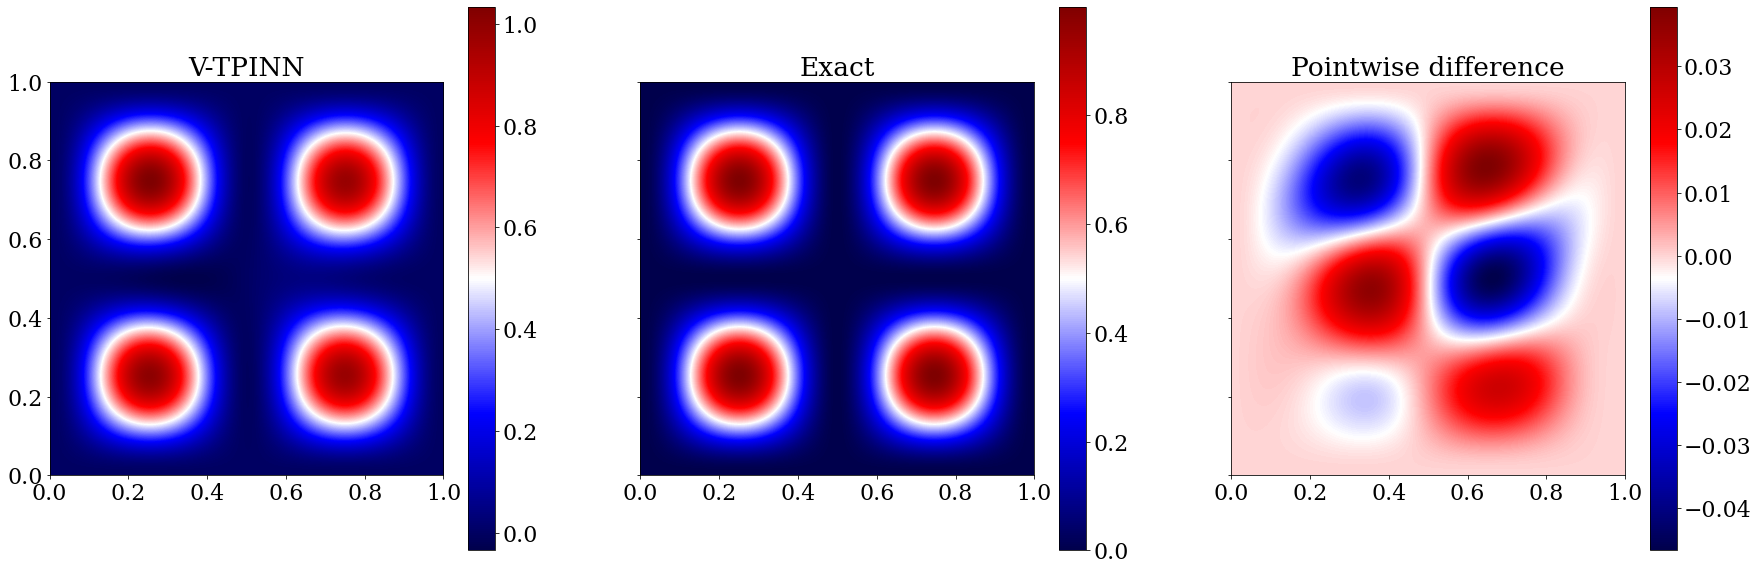

In [13]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_exact = func(points_4d)
u_sca = model.predict(points_4d)
u_exact = u_exact.reshape((Nx, Ny))
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run




diff = u_exact-u_sca
error = np.linalg.norm(diff)/np.linalg.norm(u_exact)
print('Relative error = ', error)

'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize = (30,10))


pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='V-TPINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)

pcm = ax2.imshow(np.fliplr(u_exact).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label = 'Exact')


fig.colorbar(pcm, ax = ax2)

pcm = ax3.imshow(np.fliplr(diff).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label = 'Exact')

ax3.set_title('Pointwise difference')


#ax2.scatter(data.test_x[:, 0:1], data.test_x[:, 1:2])
#ax1.scatter(data.train_x[:, 0:1], data.train_x[:, 1:2])
#ax1.axis('off')
ax1.set_title('V-TPINN')
ax2.set_title('Exact')

fig.colorbar(pcm, ax = ax3)

plt.savefig('solhelm.pdf')